In [1]:
import os
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
from jupyter_server.transutils import base_dir


In [2]:

def extract_population_from_json_file(json_file):
    """
    Extracts the population number from the json_file name.
    """
    match = re.search(r"program_pop_(\d+)", json_file)
    return int(match.group(1)) if match else None

def extract_ue_flag_from_json_file(run_folder):
    """
    Extracts the ue_flag from the json_file name.
    """
    # check if ue_True in json_file name if so return True else False
    return "ueTrue" in run_folder

def extract_ui_flag_from_json_file(run_folder):
    """
    Extracts the ui_flag from the json_file name.
    """
    # check if ue_True in json_file name if so return True else False
    return "uiTrue" in run_folder

def extract_ui_type_from_json_file(run_folder):
    """
    Extracts the ui_type from the json_file name.
    """
    try:
        return run_folder.split("uitype")[1]
    except:
        return "None"
    
# extract prompt strategy from json_file
def extract_prompt_strategy_from_json_file(json_file):
    """
    Extracts the prompt strategy from the json_file name.
    """
    try:
        return json_file.split("_")[4]
    except:
        return "None"




def extract_offspring_data_from_json_data(model_folder, json_file, run_folder, json_data):
    """
    Extracts detailed data from each element in the 'p' field and other relevant fields.
    Returns a list of flattened dictionaries.
    """
    data_records = []

    data_records.append({
            "model_folder": model_folder,
            "model": json_data.get("full_request").get("model"),
            "run_folder": run_folder,
            "json_file": json_file,
            "population": extract_population_from_json_file(json_file),
            "ue_flag": extract_ue_flag_from_json_file(run_folder),
            "ui_flag": extract_ui_flag_from_json_file(run_folder),
            "ui_type": extract_ui_type_from_json_file(run_folder),
            "algorithm": json_data.get("offspring").get("algorithm")[0],
             # Join list of strings into a single string except last and first element
            "code": " ".join(json_data.get("offspring").get("code")),#[1:-1]),"code": "\n".join(json_data.get("offspring").get("code")), 
            "objective": json_data.get("offspring").get("objective"),
            "evaluation_time": json_data.get("offspring").get("evaluation_time"),
            "offspring_id": json_data.get("offspring").get("offspring_id"),
            "prompt_strategy": extract_prompt_strategy_from_json_file(json_file),
        })
    #print(data_records)
    return data_records


def read_and_process_runs(base_directory, filter_model_folders):
    """
    Reads JSON data from all 'all_programs' folders in the given directory
    and extracts detailed data into a Pandas DataFrame.
    Only processes specified `filter_model_folders`.
    """
    all_data_records = []

    # Iterate through the base directory structure
    for model_folder in os.listdir(base_directory):
        if model_folder not in filter_model_folders:
            continue  # Skip model folders not in the filter list

        model_path = os.path.join(base_directory, model_folder)
        if os.path.isdir(model_path):
            print("Processing model folder:", model_folder)
            for experiment_folder in os.listdir(model_path):
                experiment_path = os.path.join(model_path, experiment_folder)
                if os.path.isdir(experiment_path):
                    all_programs_folder = os.path.join(experiment_path, "all_programs")
                    if os.path.exists(all_programs_folder) and os.path.isdir(all_programs_folder):
                        json_files = [f for f in os.listdir(all_programs_folder) if f.endswith(".json")]
                        for json_file in json_files:
                            file_path = os.path.join(all_programs_folder, json_file)
                            try:
                                with open(file_path, 'r') as file:
                                    json_data = json.load(file)
                                    all_data_records.extend(
                                            extract_offspring_data_from_json_data(
                                                model_folder, json_file, experiment_folder, json_data
                                            )
                                        )
                            except Exception as e:
                                #print(f"Error processing file {file_path}: {e}")
                                pass

    # Create a DataFrame from all collected records
    df = pd.DataFrame(all_data_records) if all_data_records else pd.DataFrame()
    return df



if __name__ == "__main__":
    base_dir = r"C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_results"
    filter_model_folders = [
        "diversity_folder",
    ]

    # Process the runs and extract data
    results_df = read_and_process_runs(base_dir, filter_model_folders)
    

    # Print the results
    results_df


Processing model folder: diversity_folder


In [3]:
def assign_experiment(row):
    """
    Assigns an experiment type based on ue_flag, ui_flag, and ui_type.
    """
    if row["ue_flag"] and row["ui_flag"]:
        return f"CEoH + {row['ui_type']}"
    elif row["ue_flag"]:
        return "CEoH"
    elif row["ui_flag"]:
        return f"EoH + {row['ui_type']}"
    elif row["ue_flag"] == False and row["ui_flag"] == False:
        return "EoH"
    else:
        return None

results_df["experiment"] = results_df.apply(assign_experiment, axis=1)

In [4]:
results_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6263 entries, 0 to 6262
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   model_folder     6263 non-null   object 
 1   model            6263 non-null   object 
 2   run_folder       6263 non-null   object 
 3   json_file        6263 non-null   object 
 4   population       6263 non-null   int64  
 5   ue_flag          6263 non-null   bool   
 6   ui_flag          6263 non-null   bool   
 7   ui_type          6263 non-null   object 
 8   algorithm        6263 non-null   object 
 9   code             6263 non-null   object 
 10  objective        6263 non-null   float64
 11  evaluation_time  6263 non-null   int64  
 12  offspring_id     6263 non-null   object 
 13  prompt_strategy  6263 non-null   object 
 14  experiment       6263 non-null   object 
dtypes: bool(2), float64(1), int64(2), object(10)
memory usage: 648.4+ KB


In [5]:
import os
import autopep8
import tempfile
import tree_sitter_python as tspython
from tree_sitter import Language, Parser

# Load Python parser for tree-sitter
PY_LANGUAGE = Language(tspython.language())
parser = Parser(PY_LANGUAGE)

def format_python_code(code_str):
    """Formats Python code using autopep8 for consistent structure."""
    with tempfile.NamedTemporaryFile('w', delete=False, suffix='.py') as temp_file:
        temp_file.write(code_str)
        temp_filename = temp_file.name

    autopep8_args = ['--in-place', '--aggressive', '--aggressive', temp_filename]
    autopep8.fix_file(temp_filename, options=autopep8.parse_args(autopep8_args))

    with open(temp_filename, 'r') as temp_file:
        formatted_code = temp_file.read()

    return formatted_code

def remove_comments_and_docstrings(code):
    """Removes comments and docstrings from Python code using tree-sitter."""
    tree = parser.parse(bytes(code, "utf8"))
    root_node = tree.root_node

    lines = code.split('\n')
    to_remove = []

    def is_comment(node):
        return node.type == 'comment'

    def is_docstring(node):
        return (node.type == 'string' and
                (node.parent.type in ['expression_statement', 'module']))

    def traverse(node):
        if is_comment(node) or is_docstring(node):
            to_remove.append((node.start_point, node.end_point))
        for child in node.children:
            traverse(child)

    traverse(root_node)

    for start, end in reversed(to_remove):
        start_row, start_col = start
        end_row, end_col = end
        if start_row == end_row:
            lines[start_row] = lines[start_row][:start_col] + lines[start_row][end_col:]
        else:
            lines[start_row] = lines[start_row][:start_col]
            for row in range(start_row + 1, end_row):
                lines[row] = ''
            lines[end_row] = lines[end_row][end_col:]

    cleaned_lines = [line for line in lines if line.strip() != '']
    return '\n'.join(cleaned_lines)

def preprocess_code(code):
    """Applies formatting and removes comments/docstrings before embedding."""
    # handle UnicodeEncodeError: 'charmap' codec can't encode character '\u2011' in position 115: character maps to <undefined>
    code = code.encode('ascii', 'ignore').decode('ascii')
    formatted_code = format_python_code(code)
    cleaned_code = remove_comments_and_docstrings(formatted_code)
    return cleaned_code

# clean code in dataframe
results_df["code"] = results_df["code"].apply(preprocess_code)


In [6]:
# print first 5 code entries complely 
for code in results_df["code"].head():
    print(code)
    print("\n\n")

def select_next_move(warehouse_states):
    scores = []
    for state in warehouse_states:
        score = 0
        for stack in state:
            for i, load in enumerate(stack):
                score += load / (i + 1)
        scores.append(score)
    return scores



def select_next_move(warehouse_states):
    scores = []
    for state in warehouse_states:
        score = 0
        for stack in state:
            for i, load in enumerate(stack):
                if i == 0:
                    score += 2 * load  
                else:
                    blocking_penalty = 0
                    for j in range(i + 1, len(stack)):
                        if stack[j] > load:
                            blocking_penalty += stack[j]
                            break
                    score += load - blocking_penalty
        scores.append(score)
    return scores



def select_next_move(warehouse_states):
    scores = []
    for state in warehouse_states:
        score = 0
        for st

In [7]:
results_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6263 entries, 0 to 6262
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   model_folder     6263 non-null   object 
 1   model            6263 non-null   object 
 2   run_folder       6263 non-null   object 
 3   json_file        6263 non-null   object 
 4   population       6263 non-null   int64  
 5   ue_flag          6263 non-null   bool   
 6   ui_flag          6263 non-null   bool   
 7   ui_type          6263 non-null   object 
 8   algorithm        6263 non-null   object 
 9   code             6263 non-null   object 
 10  objective        6263 non-null   float64
 11  evaluation_time  6263 non-null   int64  
 12  offspring_id     6263 non-null   object 
 13  prompt_strategy  6263 non-null   object 
 14  experiment       6263 non-null   object 
dtypes: bool(2), float64(1), int64(2), object(10)
memory usage: 648.4+ KB


In [8]:
print(results_df.head(10))

       model_folder              model  \
0  diversity_folder  gpt-4o-2024-08-06   
1  diversity_folder  gpt-4o-2024-08-06   
2  diversity_folder  gpt-4o-2024-08-06   
3  diversity_folder  gpt-4o-2024-08-06   
4  diversity_folder  gpt-4o-2024-08-06   
5  diversity_folder  gpt-4o-2024-08-06   
6  diversity_folder  gpt-4o-2024-08-06   
7  diversity_folder  gpt-4o-2024-08-06   
8  diversity_folder  gpt-4o-2024-08-06   
9  diversity_folder  gpt-4o-2024-08-06   

                                          run_folder  \
0  results_20241216_002106_multibay_reshuffle_gpt...   
1  results_20241216_002106_multibay_reshuffle_gpt...   
2  results_20241216_002106_multibay_reshuffle_gpt...   
3  results_20241216_002106_multibay_reshuffle_gpt...   
4  results_20241216_002106_multibay_reshuffle_gpt...   
5  results_20241216_002106_multibay_reshuffle_gpt...   
6  results_20241216_002106_multibay_reshuffle_gpt...   
7  results_20241216_002106_multibay_reshuffle_gpt...   
8  results_20241216_002106_multib

In [9]:
import torch
import numpy as np
import pandas as pd
import os
from transformers import AutoModel, AutoTokenizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.cluster import DBSCAN

# ------------------- Model Setup -------------------
checkpoint = "microsoft/codebert-base"  # CodeBERT (better for syntax & structural differences)
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(checkpoint, trust_remote_code=True)
model = AutoModel.from_pretrained(checkpoint, trust_remote_code=True).to(device)

# ------------------- Embedding Functions -------------------

def preprocess_code(code):
    """Preprocess the code snippet (placeholder for actual preprocessing)."""
    return code.strip()

def get_embedding(code):
    """Generates an embedding for the given code snippet after preprocessing."""
    preprocessed_code = preprocess_code(code)  # Preprocess first

    inputs = tokenizer.encode_plus(
        preprocessed_code, return_tensors="pt", truncation=True, max_length=512
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        embedding = outputs.last_hidden_state.mean(dim=1).cpu().numpy()  # Mean pooling

    return embedding.flatten()

def compute_cosine_similarity(embeddings):
    """Computes cosine similarity between embeddings."""
    return cosine_similarity(embeddings)

# ------------------- Clustering Functions -------------------

def cluster_nodes_dbscan(embeddings, eps=0.2):
    """Clusters embeddings using DBSCAN (detects outliers)."""
    clustering = DBSCAN(eps=eps, min_samples=2, metric='cosine').fit(embeddings)
    return clustering.labels_

def cluster_nodes(similarity_matrix, threshold=0.8):
    """Clusters embeddings using hierarchical clustering."""
    distance_matrix = 1 - similarity_matrix
    distance_matrix = np.clip(distance_matrix, 0, None)
    condensed_distance_matrix = squareform(distance_matrix)
    Z = linkage(condensed_distance_matrix, method='complete')
    clusters = fcluster(Z, t=1 - threshold, criterion='distance')
    return clusters

# ------------------- Diversity Metrics -------------------

def calculate_shannon_diversity(clusters):
    """Computes Shannon Diversity Index based on cluster distribution."""
    total_nodes = len(clusters)
    unique, counts = np.unique(clusters, return_counts=True)
    proportions = counts / total_nodes
    shannon_index = -np.sum(proportions * np.log(proportions))
    return shannon_index

def calculate_cdi(embeddings):
    """Computes Community Diversity Index (CDI) using Minimum Spanning Tree (MST)."""
    embeddings_matrix = np.vstack(embeddings)
    distance_matrix = np.linalg.norm(embeddings_matrix[:, None] - embeddings_matrix, axis=2)
    mst = minimum_spanning_tree(distance_matrix).toarray()
    mst_distances = mst[mst != 0]
    total_distance = np.sum(mst_distances)
    proportions = mst_distances / total_distance
    diversity_index = -np.sum(proportions * np.log(proportions))
    return diversity_index

# ------------------- Main Diversity Computation -------------------

def compute_embedding_diversity(df, threshold=0.8, group_by=None, use_dbscan=False, output_dir_cdi="diversity_analysis"):
    """Computes diversity metrics for given code snippets and saves CDI & Shannon separately per group."""
    
    # Create output directory if it does not exist
    os.makedirs(output_dir, exist_ok=True)

    if group_by:
        grouped = df.groupby(group_by)
    else:
        grouped = [('overall', df)]

    for group_name, group_df in grouped:
        print(f"\nProcessing group: {group_name}")
        code_snippets = group_df['code'].tolist()
        embeddings = [get_embedding(code) for code in code_snippets]

        print(f"Generated {len(embeddings)} embeddings for group {group_name}")

        if len(embeddings) < 2:
            print(f"Skipping group {group_name} (only {len(embeddings)} snippet)")
            continue 

        # Compute separate diversity metrics
        #shannon_diversity_index = calculate_shannon_diversity(clusters)
        cdi = calculate_cdi(embeddings)

        result = {
            "model_folder": group_df["model_folder"].values[0],
            "group": group_name,
            "population": group_df["population"].values[0],
            "experiment": group_df["experiment"].values[0],
            "model": group_df["model"].values[0],
            "run_folder": group_df["run_folder"].values[0],
            "prompt_strategy": group_df["prompt_strategy"].values[0],
            
            "max_objective": group_df["objective"].max(),
            "min_objective": group_df["objective"].min(),
            "median_objective": group_df["objective"].median(),
            "mean_objective": group_df["objective"].mean(),
            "std_objective": group_df["objective"].std(),
            
            "total_diversity_cdi": cdi,
        }

        # Convert to DataFrame
        result_df = pd.DataFrame([result])

        # File names (sanitize group names for safe filenames)
        sanitized_group_name = re.sub(r'[^a-zA-Z0-9._-]', '_', str(group_name))

        # create folder for model folder 
        os.makedirs(os.path.join(output_dir_cdi, group_df["run_folder"].values[0]), exist_ok=True)
        print(f"Created folder for model folder: {group_df['run_folder'].values[0]}")
        
        # save files to model folder 
        cdi_file = os.path.join(output_dir_cdi, group_df["run_folder"].values[0], f"diversity_{sanitized_group_name}.csv")

        # Save total_diversity_cdi to separate files with all results
        cdi_measures = ["model_folder", "group", "population", "experiment", "model", "run_folder","prompt_strategy", 
                        "max_objective", "min_objective", "median_objective", "mean_objective", "std_objective",
                        "total_diversity_cdi"]
        result_df[cdi_measures].to_csv(cdi_file, index=False)

        print(f"Processed group: {group_name} â†’ Saved CDI to {cdi_file}")

    print(f"\nAll results saved in '{output_dir_cdi}' directory.")
    
    return result_df

# ------------------- Run Analysis -------------------

output_dir = r"C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_analysis"
os.makedirs(os.path.join(output_dir, "diversity_analysis"), exist_ok=True)
output_dir_cdi = os.path.join(output_dir, "diversity_analysis")

# Load your dataset (Assuming 'results_df' is preloaded with the required columns)
# Sort results_df by model, run_folder, population, experiment
results_df = results_df.sort_values(by=['model', 'run_folder', 'population', 'experiment', 'prompt_strategy'], ascending=False)

# Filter dataset for populations less than 10
results_df_filter = results_df[results_df['population'] < 30]

# Compute diversity grouped by model, run_folder, population, and experiment
#diversity_df_grouped = compute_embedding_diversity(
#    results_df_filter, threshold=0.95, group_by=['model', 'run_folder', 'population', 'experiment', 'prompt_strategy'], use_dbscan=True, output_dir_cdi=output_dir_cdi
#)

# save overall diversity to seperate folder
output_dir = r"C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_analysis"
os.makedirs(os.path.join(output_dir, "diversity_analysis"), exist_ok=True)
output_dir_cdi_overall = os.path.join(output_dir, "diversity_analysis_overall")

# compute the overall diversity
#diversity_df_overall = compute_embedding_diversity(
#    results_df_filter, threshold=0.95, group_by=['model', 'run_folder'], use_dbscan=True, output_dir_cdi=output_dir_cdi_overall
#)


C:\Users\smthboem\PycharmProjects\multibay-reshuffling\.venv310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# ------------------- Main Diversity Computation -------------------

import torch, numpy as np, pandas as pd, os, re
from transformers import AutoModel, AutoTokenizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.cluster import DBSCAN

# Model setup
checkpoint = "microsoft/codebert-base"
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(checkpoint, trust_remote_code=True)
model = AutoModel.from_pretrained(checkpoint, trust_remote_code=True).to(device)

# Preprocessing function
def preprocess_code(code):
    return code.strip()

# Batch embedding function
def get_embeddings(codes):
    preprocessed = [preprocess_code(code) for code in codes]
    inputs = tokenizer(preprocessed, return_tensors="pt", truncation=True, max_length=512, padding=True).to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        embeddings = outputs.last_hidden_state.mean(dim=1).cpu().numpy()
    return embeddings

# CDI calculation using efficient distance computation
def calculate_cdi(embeddings):
    embeddings_matrix = np.vstack(embeddings)
    condensed_dist = pdist(embeddings_matrix, metric='euclidean')
    distance_matrix = squareform(condensed_dist)
    mst = minimum_spanning_tree(distance_matrix).toarray()
    mst_distances = mst[mst != 0]
    total_distance = np.sum(mst_distances)
    proportions = mst_distances / total_distance
    return -np.sum(proportions * np.log(proportions))

# ... (other functions remain similar)

# Main diversity computation with optimized file operations and vectorized filtering
def compute_embedding_diversity_cumulative(df, threshold=0.8, group_by=None, output_dir_cdi="diversity_analysis"):
    os.makedirs(output_dir_cdi, exist_ok=True)
    filename_regex = re.compile(r'[^a-zA-Z0-9._-]')
    grouped = df.groupby(group_by)
    all_results = []

    for group_name, group_df in grouped:
        print(f"Processing group: {group_name}")
        codes = group_df['code'].tolist()
        embeddings_group = get_embeddings(codes)  # Batch processing
        populations = group_df["population"].values
        
        for population in range(0, group_df["population"].max() + 1):
            sanitized_group_name = filename_regex.sub('_', str(group_name))
            run_folder = group_df["run_folder"].values[0]
            group_dir = os.path.join(output_dir_cdi, run_folder)
            os.makedirs(group_dir, exist_ok=True)
            cdi_file = os.path.join(group_dir, f"diversity_{sanitized_group_name}_pop_{population}.csv")
            
            if os.path.exists(cdi_file):
                print(f"Skipping group {group_name} for population {population} (file exists)")
                continue

            mask = populations <= population
            embeddings = embeddings_group[mask]
            if len(embeddings) < 2:
                print(f"Skipping group {group_name} for population {population} (not enough snippets)")
                continue 

            cdi = calculate_cdi(embeddings)
            group_df_filter = group_df[mask]
            result = {
                "model_folder": group_df_filter["model_folder"].values[0],
                "group": group_name,
                "population_limit": population,
                "experiment": group_df_filter["experiment"].values[0],
                "model": group_df_filter["model"].values[0],
                "run_folder": run_folder,
                "prompt_strategy": group_df_filter["prompt_strategy"].values[0],
                "max_objective": group_df_filter["objective"].max(),
                "min_objective": group_df_filter["objective"].min(),
                "median_objective": group_df_filter["objective"].median(),
                "mean_objective": group_df_filter["objective"].mean(),
                "std_objective": group_df_filter["objective"].std(),
                "total_diversity_cdi": cdi,
            }
            result_df = pd.DataFrame([result])
            result_df.to_csv(cdi_file, index=False)
            print(f"Processed group: {group_name} for population {population}, saved to {cdi_file}")
            all_results.append(result)

    print(f"All results saved in '{output_dir_cdi}' directory.")
    return pd.DataFrame(all_results)


# ------------------- Run Analysis -------------------

output_dir = r"C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_analysis"
os.makedirs(os.path.join(output_dir, "diversity_analysis"), exist_ok=True)
output_dir_cdi = os.path.join(output_dir, "diversity_analysis")

prompt_strategy_order = ['i1', 'e1', 'e2', 'p1', 'm1', 'm2']

# Load your dataset (Assuming 'results_df' is preloaded with the required columns)
# Sort results_df by model, run_folder, population, experiment and sort prompt_strategy by prompt_strategy_order 
results_df = results_df.sort_values(by=['model', 'run_folder', 'population', 'experiment', 'prompt_strategy'], ascending=False)
results_df["prompt_strategy"] = pd.Categorical(results_df["prompt_strategy"], categories=prompt_strategy_order, ordered=True)


# Filter dataset for populations less than 10
results_df_filter = results_df[results_df['population'] < 20]

# filter 10 rows per population
#results_df_filter = results_df_filter.groupby(['model', 'run_folder', 'population', 'experiment', 'prompt_strategy']).head(2)

# save overall diversity to seperate folder
output_dir = r"C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_analysis"
os.makedirs(os.path.join(output_dir, "diversity_analysis"), exist_ok=True)
output_dir_cdi_overall = os.path.join(output_dir, "diversity_analysis_overall")


# compute the overall diversity
diversity_df_overall = compute_embedding_diversity_cumulative(
    results_df_filter, threshold=0.95, group_by=['model', 'run_folder',"experiment"], output_dir_cdi=output_dir_cdi_overall
)


NameError: name 'results_df' is not defined

In [27]:
diversity_df_overall

,model_folder,group,population_limit,experiment,model,run_folder,prompt_strategy,max_objective,min_objective,median_objective,mean_objective,std_objective,total_diversity_cdi
0,diversity_folder,"(gemma2:27b, results_bp_online_gemma227b_20241...",18,EoH,gemma2:27b,results_bp_online_gemma227b_20241115_105856,m2,1.51534,0.00584,0.046835,0.301898,0.40519,4.98467


In [13]:
import os
import pandas as pd

# list all directories in C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_analysis\diversity_analysis
directories = [x[0] for x in os.walk(r"C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_analysis\diversity_analysis_overall")]

# filter directories to only include directories with files
filter = False
if filter:
    directories = [r"C:\Users\smthboem\PycharmProjects\multibay-reshuffling\eoh_analysis\diversity_analysis\results_bp_online_gemma227b_20241115_105856"]

# List to store DataFrames
df_list = []

# Iterate through each directory and read CSV files
for directory in directories:
    if os.path.exists(directory):  # Check if directory exists
        csv_files = [os.path.join(directory, file) for file in os.listdir(directory) if file.endswith('.csv')]
        for file in csv_files:
            df_list.append(pd.read_csv(file))

# Concatenate all DataFrames
if df_list:
    combined_df = pd.concat(df_list, ignore_index=True)
    
    # Display the concatenated DataFrame
    display(combined_df)
    combined_df.info()
else:
    print("No CSV files found in the specified directories.")


,model_folder,group,population_limit,experiment,model,run_folder,prompt_strategy,max_objective,min_objective,median_objective,mean_objective,std_objective,total_diversity_cdi
0,save_server_0.6_gemma,"('gemma2:27b', 'results_20241129_104935_multib...",0,EoH,gemma2:27b,results_20241129_104935_multibay_reshuffle_gem...,m2,13.9329,8.53885,13.93290,12.517844,1.935272,4.439066
1,save_server_0.6_gemma,"('gemma2:27b', 'results_20241129_104935_multib...",1,EoH,gemma2:27b,results_20241129_104935_multibay_reshuffle_gem...,m2,13.9329,7.66623,13.93290,12.675421,1.875786,5.030686
2,save_server_0.6_gemma,"('gemma2:27b', 'results_20241129_104935_multib...",10,EoH,gemma2:27b,results_20241129_104935_multibay_reshuffle_gem...,m2,13.9329,0.56269,10.69957,10.366962,3.362614,6.539841
3,save_server_0.6_gemma,"('gemma2:27b', 'results_20241129_104935_multib...",11,EoH,gemma2:27b,results_20241129_104935_multibay_reshuffle_gem...,m2,13.9329,0.56269,9.73082,10.273487,3.379841,6.620644
4,save_server_0.6_gemma,"('gemma2:27b', 'results_20241129_104935_multib...",12,EoH,gemma2:27b,results_20241129_104935_multibay_reshuffle_gem...,m2,13.9329,0.56269,9.56147,10.145757,3.398023,6.699640
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2071,gpt4o20240806_ueTrue_uiTrue,"('gpt-4o-2024-08-06', 'results_20250228_061454...",1,CEoH + STR,gpt-4o-2024-08-06,results_20250228_061454_multibay_reshuffle_gpt...,p1,13.9329,3.07965,10.79957,11.046522,2.657426,5.059408
2072,gpt4o20240806_ueTrue_uiTrue,"('gpt-4o-2024-08-06', 'results_20250228_061454...",2,CEoH + STR,gpt-4o-2024-08-06,results_20250228_061454_multibay_reshuffle_gpt...,p1,13.9329,1.10524,10.76623,10.415886,3.238392,5.363085
2073,gpt4o20240806_ueTrue_uiTrue,"('gpt-4o-2024-08-06', 'results_20250228_061454...",3,CEoH + STR,gpt-4o-2024-08-06,results_20250228_061454_multibay_reshuffle_gpt...,p1,13.9329,0.33618,10.76623,9.889469,3.840989,5.573428
2074,gpt4o20240806_ueTrue_uiTrue,"('gpt-4o-2024-08-06', 'results_20250228_061454...",4,CEoH + STR,gpt-4o-2024-08-06,results_20250228_061454_multibay_reshuffle_gpt...,p1,13.9329,0.33618,10.69957,9.263400,4.352156,5.763052


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2076 entries, 0 to 2075
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_folder         2076 non-null   object 
 1   group                2076 non-null   object 
 2   population_limit     2076 non-null   int64  
 3   experiment           2076 non-null   object 
 4   model                2076 non-null   object 
 5   run_folder           2076 non-null   object 
 6   prompt_strategy      2076 non-null   object 
 7   max_objective        2076 non-null   float64
 8   min_objective        2076 non-null   float64
 9   median_objective     2076 non-null   float64
 10  mean_objective       2076 non-null   float64
 11  std_objective        2076 non-null   float64
 12  total_diversity_cdi  2076 non-null   float64
dtypes: float64(6), int64(1), object(6)
memory usage: 211.0+ KB


In [14]:
# filter only reshuffle results
combined_df = combined_df[combined_df['run_folder'].str.contains("reshuffle")]

#exclude google
combined_df = combined_df[~combined_df['run_folder'].str.contains("google")]

In [15]:
# print the maximum population for each run_folder
combined_df.groupby('run_folder')['population_limit'].max()

run_folder
results_20241129_104935_multibay_reshuffle_gemma227b_ueFalse                         19
results_20241129_141130_multibay_reshuffle_gemma227b_ueFalse                         19
results_20241130_181952_multibay_reshuffle_gemma227b_ueFalse                         19
results_20241201_051354_multibay_reshuffle_gemma227b_ueFalse                         19
results_20241201_083614_multibay_reshuffle_gemma227b_ueFalse                         19
                                                                                     ..
results_20250227_135503_multibay_reshuffle_qwen25coder32b_ueTrue_uiTrue_uitypeSTR    19
results_20250227_154928_multibay_reshuffle_gpt4o20240806_ueTrue_uiTrue_uitypeSTR     19
results_20250227_201553_multibay_reshuffle_gpt4o20240806_ueTrue_uiTrue_uitypeSTR     19
results_20250228_012515_multibay_reshuffle_gpt4o20240806_ueTrue_uiTrue_uitypeSTR     19
results_20250228_061454_multibay_reshuffle_gpt4o20240806_ueTrue_uiTrue_uitypeSTR      5
Name: population_limi

In [16]:
combined_df["model"].unique()

array(['gemma2:27b', 'qwen2.5-coder:32b', 'gpt-4o-2024-08-06'],
      dtype=object)

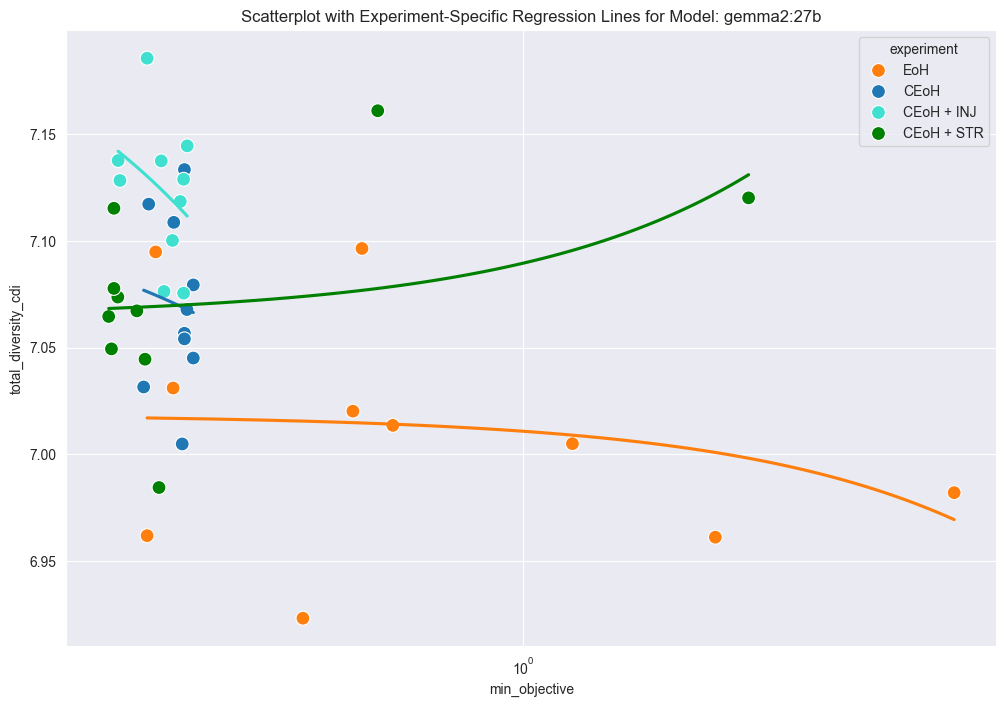

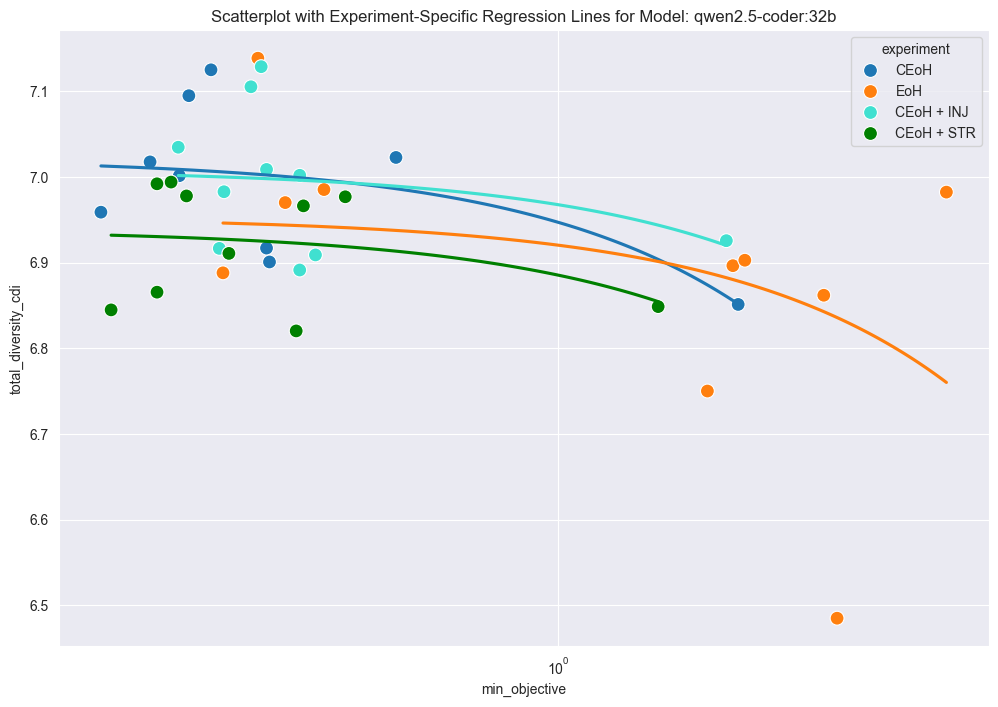

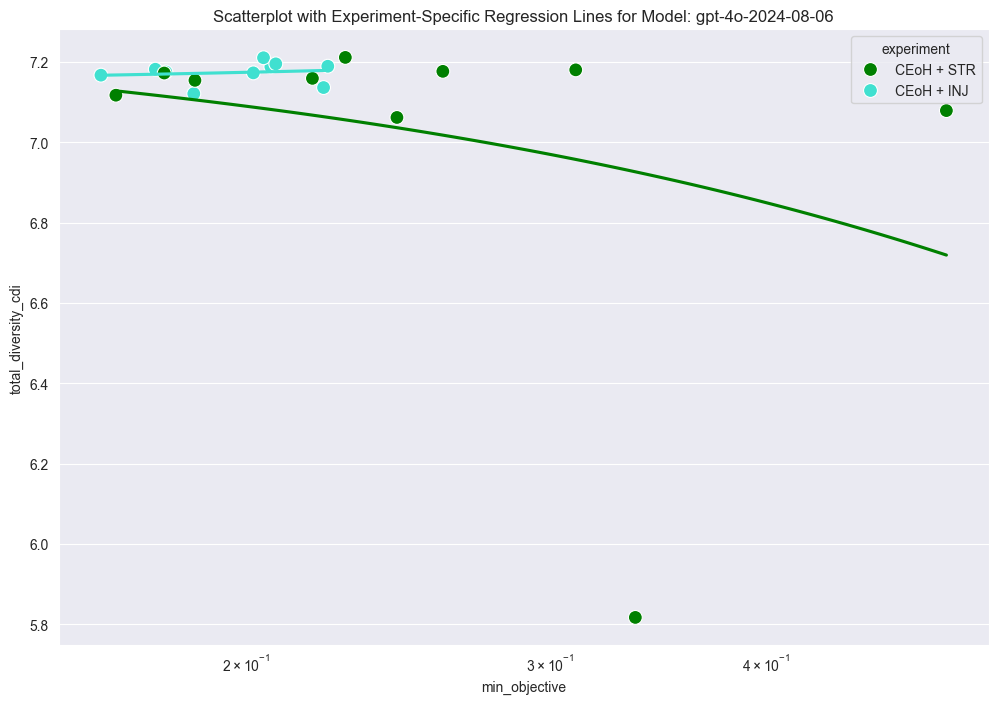

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Group by 'run_folder' to get the highest total_diversity_cdi and lowest min_objective per run_folder
agg_df = combined_df.groupby('run_folder').agg({
    "experiment": "first",
    "model": "first",
    "total_diversity_cdi": "max",
    "min_objective": "min"
}).reset_index()

# Define custom color mapping for experiments
color_map = {
    'EoH + None': '#ff7f0e',
    'EoH': '#ff7f0e',
    'CEoH + None': "#1f77b4",
    'CEoH': "#1f77b4",
    "CEoH + STR": 'green',
    "CEoH + INJ": 'turquoise',
    "CEoH + STR_E2": 'purple',
}

# Get unique models in the data
models = agg_df['model'].unique()

# Loop through each model and create a separate plot
for m in models:
    model_data = agg_df[agg_df['model'] == m]
    
    plt.figure(figsize=(12, 8))
    
    # Create scatterplot with points colored by experiment
    sns.scatterplot(
        data=model_data,
        x="min_objective",
        y="total_diversity_cdi",
        hue="experiment",
        palette=color_map,
        s=100
    )
    
    # Loop over each experiment in this model to add its own regression line
    unique_experiments = model_data['experiment'].unique()
    for exp in unique_experiments:
        subset = model_data[model_data['experiment'] == exp]
        if len(subset) > 1:  # Only add a regression line if there are multiple data points
            sns.regplot(
                data=subset,
                x="min_objective",
                y="total_diversity_cdi",
                scatter=False,
                ci=None,
                color=color_map.get(exp, 'black')
            )
    
    # Set x-axis to log scale
    plt.xscale('log')
    plt.title(f'Scatterplot with Experiment-Specific Regression Lines for Model: {m}')
    plt.show()


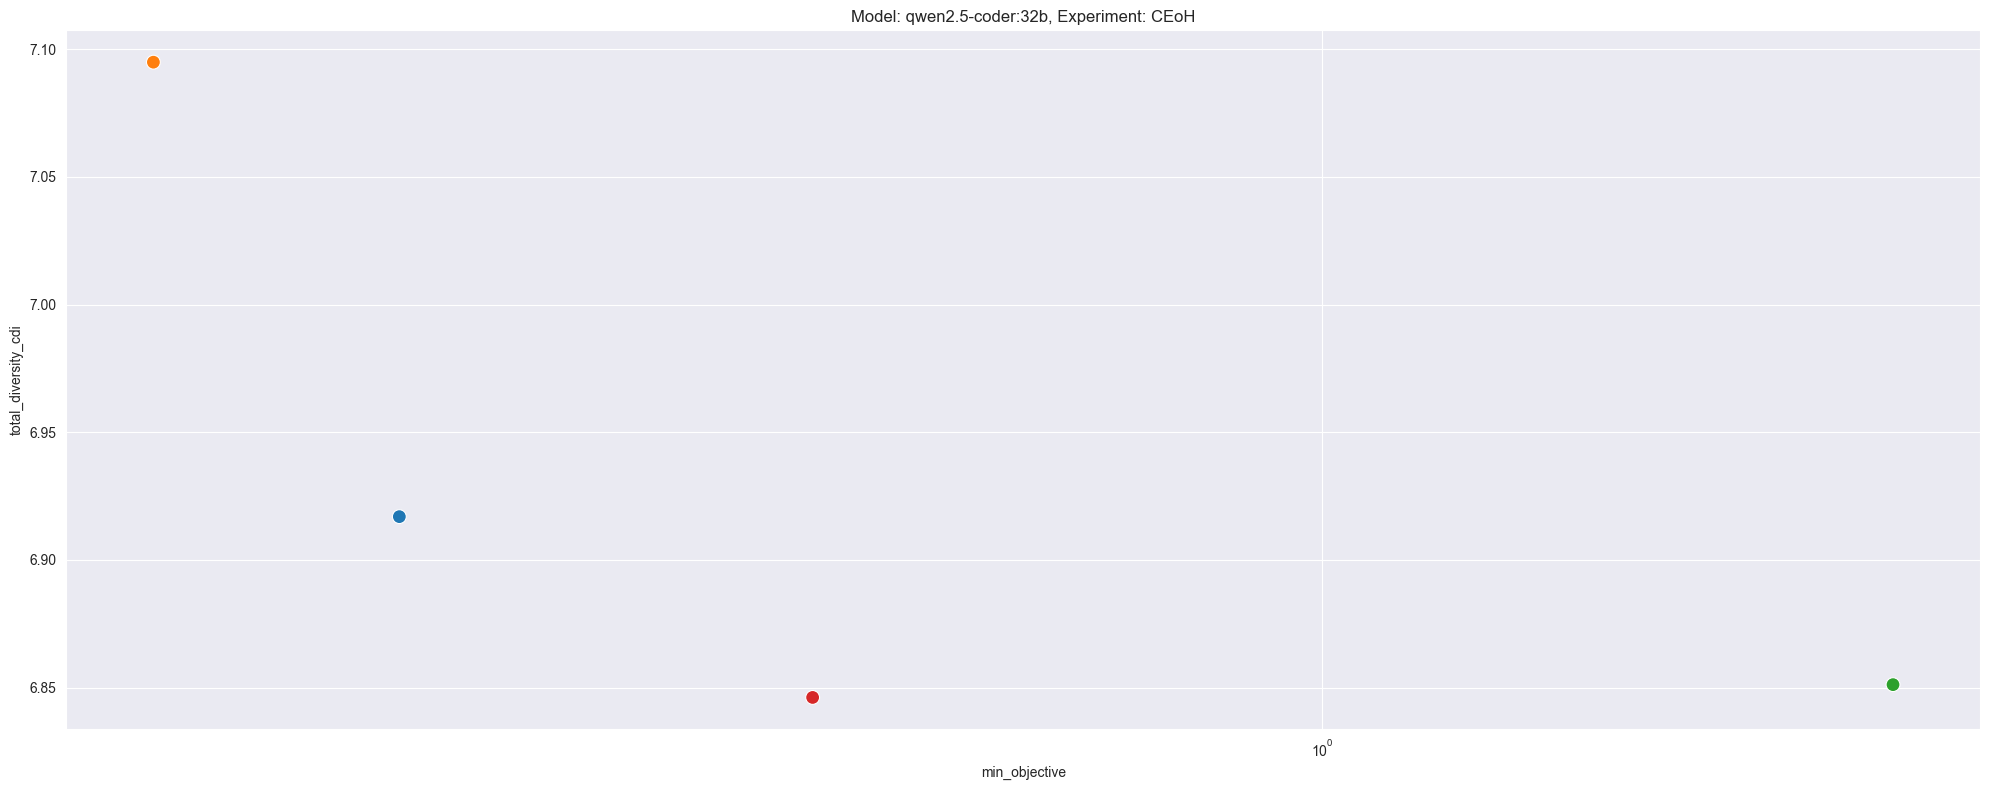

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique models and experiments
unique_models = agg_df["model"].unique()
unique_experiments = agg_df["experiment"].unique()

# Create subplots for each model and experiment combination
fig, axes = plt.subplots(len(unique_models), len(unique_experiments), figsize=(20, 8), sharex=True, sharey=True)

# Flatten axes for easier iteration if there are multiple subplots
if len(unique_models) > 1 and len(unique_experiments) > 1:
    axes = axes.flatten()
else:
    axes = [axes]

# Plot each model and experiment in a separate subplot
for i, model in enumerate(unique_models):
    for j, experiment in enumerate(unique_experiments):
        ax = axes[i * len(unique_experiments) + j]
        subset = agg_df[(agg_df["model"] == model) & (agg_df["experiment"] == experiment)]
        
        sns.scatterplot(
            data=subset, 
            x="min_objective", 
            y="total_diversity_cdi", 
            hue="run_folder", 
            s=100, 
            ax=ax
        )
        
        ax.set_xscale("log")

        # scale y axis max to max in dataset
        #ax.set_ylim(subset["total_diversity_cdi"].min(), subset["total_diversity_cdi"].max())
        
        ax.set_title(f"Model: {model}, Experiment: {experiment}")
        ax.legend().remove()

# Adjust layout and show plot
plt.tight_layout()
plt.show()


C:\Users\smthboem\AppData\Local\Temp\ipykernel_11904\4130798329.py:29: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


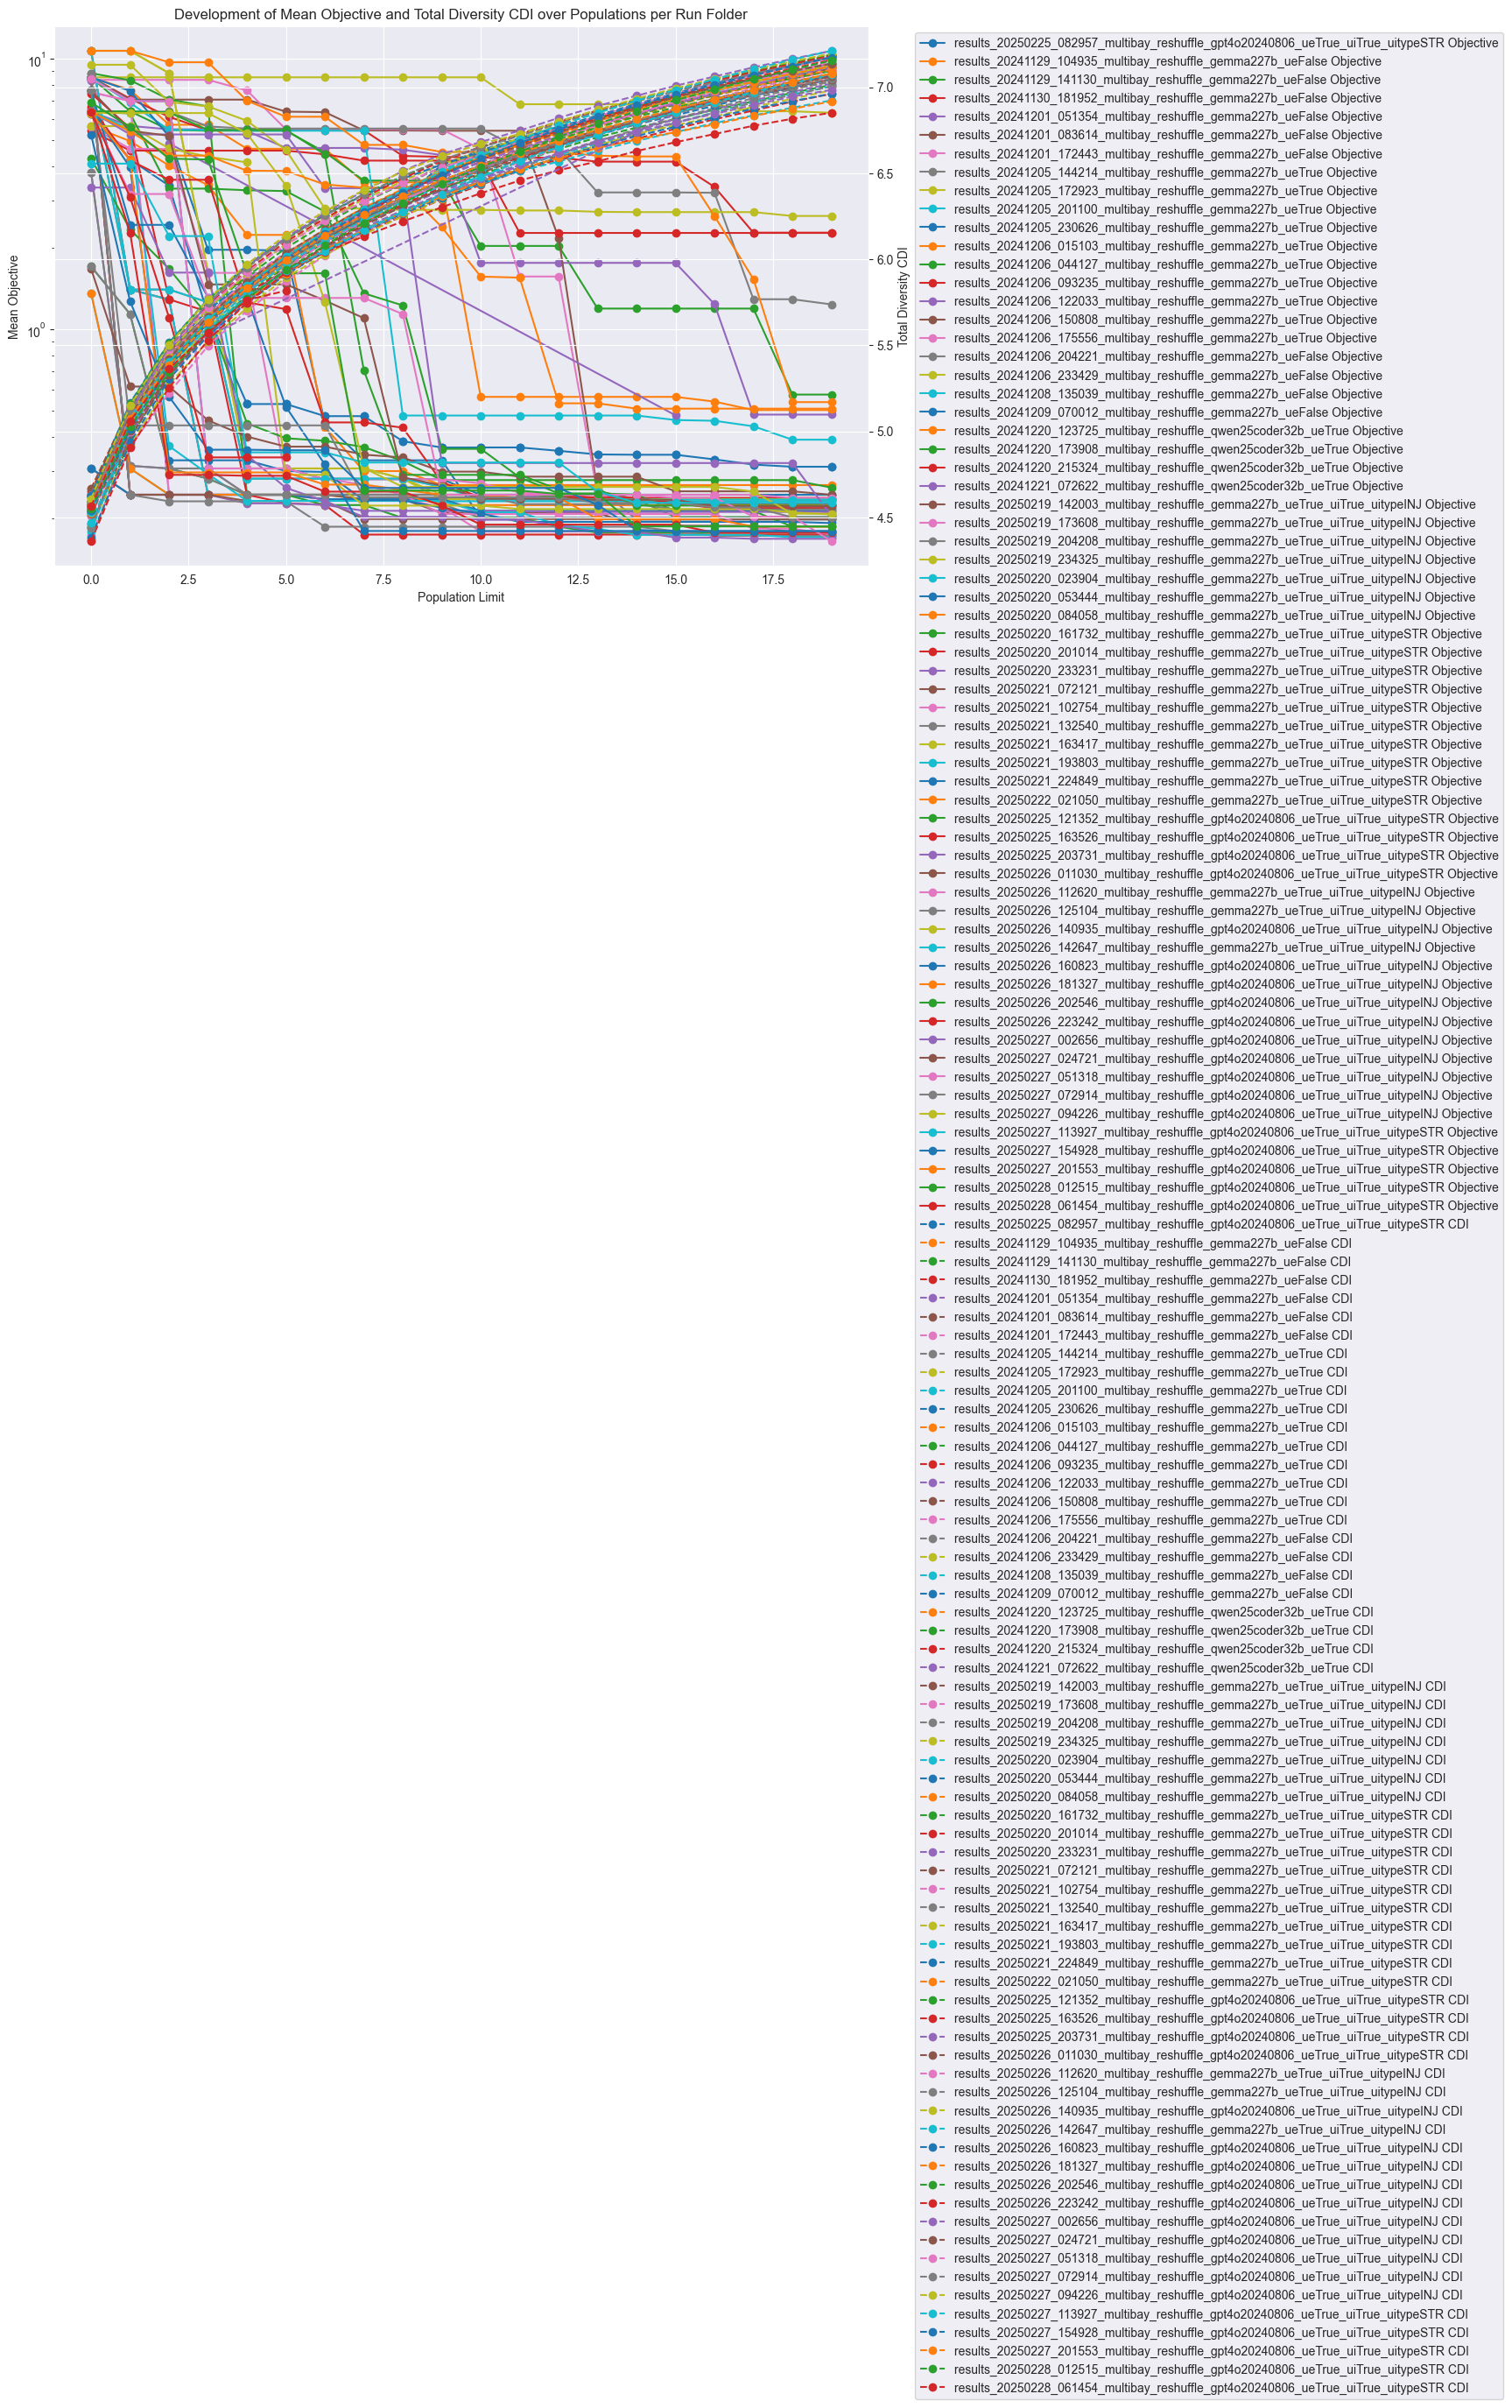

In [7]:
import matplotlib.pyplot as plt

# Create figure and twin axes
fig, ax1 = plt.subplots(figsize=(12, 8))
ax2 = ax1.twinx()

# Iterate over each run_folder and plot both mean_objective and total_diversity_cdi
for run_folder in combined_df['run_folder'].unique():
    df = combined_df[combined_df['run_folder'] == run_folder].sort_values('population_limit')
    # Plot mean_objective on ax1
    ax1.plot(df['population_limit'], df['min_objective'], marker='o', label=f'{run_folder} Objective')
    # Plot total_diversity_cdi on ax2
    ax2.plot(df['population_limit'], df['total_diversity_cdi'], marker='o', linestyle='--', label=f'{run_folder} CDI')

# Set axis labels and title
ax1.set_xlabel('Population Limit')
ax1.set_ylabel('Mean Objective')
ax2.set_ylabel('Total Diversity CDI')
plt.title('Development of Mean Objective and Total Diversity CDI over Populations per Run Folder')

# set obbjective axis to log
ax1.set_yscale('log')

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()
